In [1]:
import matplotlib.pyplot as plt
import numpy as np

from amms.core import products
from amms.core.analysis.sfr import lookback_edges, sfh, sfr_map_from_young_stars
from amms.core.datasets import b12, patel2020
from amms.core.analysis import units
from amms.core.plotting.maps import shared_norm, show_map
from amms.core.analysis.fourier import fourier_phase
from amms.core.analysis.frames import rot_z
from amms.core.analysis.maps import project_map

MODELS = (1, 2)
COLOR = {1: "C0", 2: "C3"}
DT = 0.01 # Gyr
MAP_DT = 0.1


LMC_R_MAX = 5.0
SMC_R_MAX = 2.0
GAL = {"lmc": {"r_max": LMC_R_MAX, "extent": 10.0},
       "smc": {"r_max": SMC_R_MAX, "extent": 5.0}}

In [2]:
def dataset(model):
    return f"ext_b12-model{model}"

In [3]:
def load_diskstars(model, galaxy, snap=b12.SNAP_PRESENT_DAY):
    return products.read_product(products.product_path(dataset(model), "diskstars", f"{galaxy}-{snap:03d}"))

In [4]:
def load_newstars(model, galaxy, snap=b12.SNAP_PRESENT_DAY):
    return products.read_product(products.product_path(dataset(model), "newstars", f"{galaxy}-{snap:03d}"))

In [7]:
d, ns = load_diskstars(2, "lmc"), load_newstars(2, "lmc")
# bar angle is measured on disk stars and then applied to new stars. So both must share the same frame
assert d.attrs.meta["frame"] == ns.attrs.meta["frame"]
pos_d, m_d = d.arrays["pos_kpc"], d.arrays["mass_msun"]

In [9]:
edges_R = np.arange(0.0, 6.01, 0.25)
prof = np.array([fourier_phase(pos_d, m_d, m=2, r_min=r0, r_max=r1)
                for r0, r1 in zip(edges_R[:-1], edges_R[1:])])
Rc = 0.5 * (edges_R[1:] + edges_R[:-1])

[Text(0, 0.5, '$\\phi_2$ [deg]'), Text(0.5, 0, 'R [kpc]')]

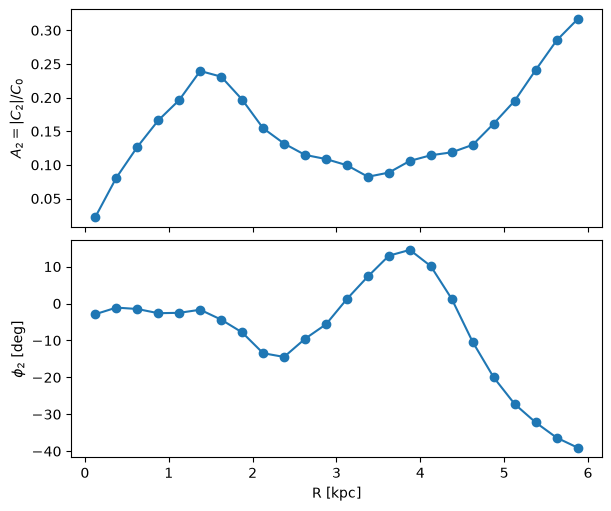

In [10]:
fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6, 5), constrained_layout=True)
a1.plot(Rc, prof[:, 1], "o-")
a1.set_ylabel(r"$A_2 = |C_2|/C_0$")
# phi2 is (-90,90]
# Unwrap on 2*phi so a bar at +-90 doesn't have a jump
a2.plot(Rc, np.degrees(np.unwrap(2 * prof[:, 0]) / 2), "o-")
a2.set(ylabel=r"$\phi_2$ [deg]", xlabel="R [kpc]")

phi2 = -4.2 deg, A2 = 0.174, alpha = -4.2 deg


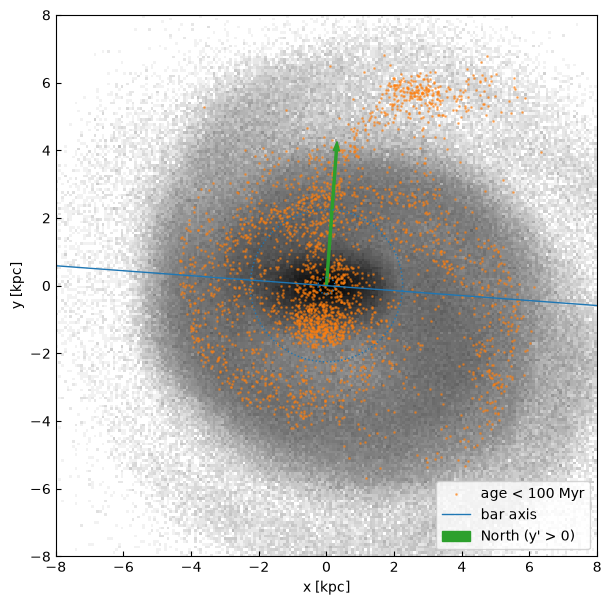

In [24]:
# Adjust the following until the bar is centered
# RECORD final values in b12.LMC_BAR_SPLIT
R_MIN, R_MAX, FLIP = 0.25, 2.25, 0

phi2, a2 = fourier_phase(pos_d, m_d, m=2, r_min=R_MIN, r_max=R_MAX)
alpha = phi2 + np.pi * FLIP
print(f"phi2 = {np.degrees(phi2):.1f} deg, A2 = {a2:.3f}, alpha = {np.degrees(alpha):.1f} deg")

ext = 8.0
dmap = project_map(pos_d, m_d, extent=ext, bins=200, per_area=True)
age = ns.attrs.meta["t_now_gyr"] - ns.arrays["t_form_gyr"]
young = ns.arrays["pos_kpc"][age < 0.1]

fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)
show_map(dmap, ax, cmap="Greys", cbar=False)
ax.scatter(young[:, 0], young[:, 1], s=1,  c="C1", alpha=0.5, label="age < 100 Myr")
L = np.array([-ext, ext])
ax.plot(L * np.cos(phi2), L * np.sin(phi2), "C0", lw=1, label="bar axis")
# rot_z(-alpha) sends the direction alpha+90 deg to +y'
# This arrow points to the "North" side
ax.arrow(0, 0, 4 * np.cos(alpha + np.pi / 2), 4 * np.sin(alpha + np.pi / 2), width=0.06, color="C2", label="North (y' > 0)")
for r in (R_MIN, R_MAX):
    ax.add_patch(plt.Circle((0, 0), r, fill=False, ls=":", color="C0"))
ax.legend(loc="lower right")

In [22]:
# Cached positions are already frame.positions()
# Need to do one more z' rotation
pos_bar = ns.arrays["pos_kpc"] @ rot_z(-alpha).T
north = pos_bar[:, 1] > 0

t_now = ns.attrs.meta["t_now_gyr"]
edges = lookback_edges(t_now, DT)
t, m = ns.arrays["t_form_gyr"], ns.arrays["mass_msun"]
inr = np.linalg.norm(pos_bar, axis=1) < GAL["lmc"]["r_max"] # Rotations do not change |r|

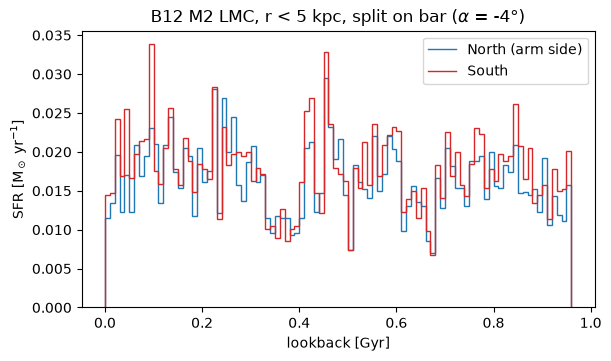

In [23]:
fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
rates = {}
for lab, s, c in (("North (arm side)", inr & north, "C0"), ("South", inr & ~north, "C3")):
    _, rates[lab] = sfh(t[s], m[s], bins=edges)
    ax.stairs(rates[lab][::-1], (t_now - edges)[::-1], color=c, label=lab)
_, total = sfh(t[inr], m[inr], bins=edges)
assert np.allclose(rates["North (arm side)"] + rates["South"], total) # Splitting should not lose any stars
ax.set(xlabel="lookback [Gyr]", ylabel=r"SFR [M$_\odot$ yr$^{-1}$]",
       title=f"B12 M2 LMC, r < {GAL['lmc']['r_max']:g} kpc, split on bar ($\\alpha$ = {np.degrees(alpha):.0f}°)")
ax.legend()